# Lab 3 | Adaptive Optimizers for ANN and MLP (MNIST)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/24pwai0015-max/deep-learning-labs/blob/main/Lab3_Adaptive_Optimizers_ANN_MLP.ipynb)

**Course:** Deep Learning Foundations | Practical Labs  
**Author:** Arsalan

This notebook trains a shallow **ANN** (one hidden layer) and a deeper **MLP** (two hidden layers) on a fixed MNIST subset (3000 train / 600 validation / 1200 test). Only the optimizer constructor changes between runs: SGD, Adam, RMSprop, Adadelta and Adagrad.

> **How to run:** In Google Colab choose *Runtime → Run all*. Keras downloads the public dataset on first use.
> Numbers (especially *seconds*) can differ slightly between machines, so always report values from **your own** run.


## 1. Settings and data preparation

In [1]:
# LAB 3: Compare SGD, Adam, RMSprop, Adadelta and Adagrad on an ANN and an MLP.
# Run in Google Colab or locally after: pip install tensorflow numpy matplotlib
# Dataset: MNIST handwritten digits, downloaded automatically by Keras on first use.

import os  # Access an environment setting that reduces TensorFlow log noise.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # Show fewer TensorFlow informational messages.
import csv  # Export an easy-to-read results table without extra packages.
import time  # Measure how long each training experiment takes.
from pathlib import Path  # Create a folder for result files on any operating system.
import numpy as np  # Select the same images for every experiment.
import matplotlib.pyplot as plt  # Create accuracy comparison graphs.
import tensorflow as tf  # Build, train and test neural networks.

SEED = 42  # Use a repeatable random seed for classroom comparisons.
TRAIN_N = 3000  # Limit training images so the lab runs quickly on any machine.
VAL_N = 600  # Keep separate validation images for model selection.
TEST_N = 1200  # Keep a separate test subset for the final evaluation.
EPOCHS = 4  # Use the same number of training epochs for every optimizer.
BATCH_SIZE = 64  # Keep the mini-batch size fixed while comparing optimizers.
OUT = Path("lab3_optimizer_results")  # Name the folder that will hold the result files.
OUT.mkdir(parents=True, exist_ok=True)  # Create the folder if it does not exist yet.
tf.keras.utils.set_random_seed(SEED)  # Set the Python, NumPy and TensorFlow seeds.

(x_all, y_all), (x_test_all, y_test_all) = tf.keras.datasets.mnist.load_data()  # Load public MNIST.
rng = np.random.default_rng(SEED)  # Create a deterministic NumPy random generator.
train_order = rng.permutation(len(x_all))  # Shuffle the original training indices one time.
test_order = rng.permutation(len(x_test_all))  # Shuffle the separate test indices one time.
selected = train_order[:TRAIN_N + VAL_N]  # Select non-overlapping train and validation indices.
x_train = x_all[selected[:TRAIN_N]].astype("float32") / 255.0  # Scale training pixels to 0..1.
y_train = y_all[selected[:TRAIN_N]]  # Select training labels using the matching indices.
x_val = x_all[selected[TRAIN_N:]].astype("float32") / 255.0  # Scale validation pixels to 0..1.
y_val = y_all[selected[TRAIN_N:]]  # Select the validation labels.
x_test = x_test_all[test_order[:TEST_N]].astype("float32") / 255.0  # Scale held-out test pixels.
y_test = y_test_all[test_order[:TEST_N]]  # Select the matching test labels.
print("Train:", x_train.shape, "| Validation:", x_val.shape, "| Test:", x_test.shape)  # Confirm sizes.


Train: (3000, 28, 28) | Validation: (600, 28, 28) | Test: (1200, 28, 28)


## 2. Model definitions and the five optimizers

In [2]:
# A shallow ANN is also technically an MLP; here "ANN" means one hidden layer.
def build_ann():  # Define the smaller one-hidden-layer network.
    return tf.keras.Sequential([  # Construct a Keras network with ordered layers.
        tf.keras.layers.Input(shape=(28, 28)),  # Receive one 28-by-28 image.
        tf.keras.layers.Flatten(),  # Convert the image into 784 numeric features.
        tf.keras.layers.Dense(64, activation="relu"),  # Learn 64 hidden features.
        tf.keras.layers.Dense(10, activation="softmax"),  # Predict the 10 digit classes.
    ])  # End the ANN model definition.

# In this lab, "MLP" means a deeper multilayer perceptron with two hidden layers.
def build_mlp():  # Define a two-hidden-layer multilayer perceptron.
    return tf.keras.Sequential([  # Construct the second Keras network.
        tf.keras.layers.Input(shape=(28, 28)),  # Receive a grayscale image.
        tf.keras.layers.Flatten(),  # Flatten 28-by-28 pixels into 784 features.
        tf.keras.layers.Dense(128, activation="relu"),  # Learn 128 first-layer features.
        tf.keras.layers.Dense(64, activation="relu"),  # Combine them in 64 deeper units.
        tf.keras.layers.Dense(10, activation="softmax"),  # Produce class probabilities.
    ])  # End the MLP model definition.

# These are illustrative starting learning rates, not necessarily the Keras defaults.
OPTIMIZERS = [  # Define the ONLY line of the experiment that changes between runs.
    ("SGD", lambda: tf.keras.optimizers.SGD(learning_rate=0.01)),  # Fixed-rate baseline.
    ("Adam", lambda: tf.keras.optimizers.Adam(learning_rate=0.001)),  # Adaptive moments.
    ("RMSprop", lambda: tf.keras.optimizers.RMSprop(learning_rate=0.001)),  # Running square average.
    ("Adadelta", lambda: tf.keras.optimizers.Adadelta(learning_rate=1.0)),  # Adaptive update scaling.
    ("Adagrad", lambda: tf.keras.optimizers.Adagrad(learning_rate=0.01)),  # Accumulated gradients.
]  # Finish the optimizer configurations.


## 3. Training loop (identical initial weights for every optimizer) and graphs

In [3]:
results = []  # Collect a summary row for each model-and-optimizer combination.
epoch_rows = []  # Collect per-epoch validation accuracy so convergence can be inspected.
for model_name, builder in [("ANN", build_ann), ("MLP", build_mlp)]:  # Test both architectures.
    tf.keras.utils.set_random_seed(SEED)  # Reproduce the initial weights for this architecture.
    reference_model = builder()  # Create one reference model to record its initial weights.
    initial_weights = reference_model.get_weights()  # Store the same starting weights for all runs.
    del reference_model  # Remove the reference because it is never trained.
    histories = {}  # Save the validation accuracy curves for this architecture.
    for opt_name, make_optimizer in OPTIMIZERS:  # Repeat for all five optimization algorithms.
        tf.keras.utils.set_random_seed(SEED)  # Reset the random ordering for a fair comparison.
        model = builder()  # Make an independent new model for this optimizer.
        model.set_weights(initial_weights)  # Guarantee identical initial model weights.
        optimizer = make_optimizer()  # Change only this optimizer choice across runs.
        model.compile(optimizer=optimizer,  # Attach the optimizer under test.
                      loss="sparse_categorical_crossentropy",  # Use the integer-label loss.
                      metrics=["accuracy"])  # Track classification accuracy.
        start = time.perf_counter()  # Start a wall-clock timer immediately before training.
        history = model.fit(x_train, y_train,  # Train on the fixed training subset.
                            validation_data=(x_val, y_val),  # Validate after every epoch.
                            epochs=EPOCHS,  # Use the same number of epochs every time.
                            batch_size=BATCH_SIZE,  # Use the same mini-batch size every time.
                            shuffle=True,  # Shuffle the training data each epoch.
                            verbose=0)  # Train without verbose progress logs.
        seconds = time.perf_counter() - start  # Calculate the elapsed training seconds.
        test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)  # Evaluate on unseen test images.
        best_val = max(history.history["val_accuracy"])  # Identify the best validation accuracy.
        histories[opt_name] = history.history["val_accuracy"]  # Store the full accuracy trend.
        results.append({  # Save the numeric outcomes of this run as one table row.
            "model": model_name,  # Architecture name (ANN or MLP).
            "optimizer": opt_name,  # Optimizer name.
            "learning_rate": round(float(optimizer.learning_rate.numpy()), 6),  # Learning rate used.
            "best_val_accuracy": round(best_val, 4),  # Best validation accuracy over the epochs.
            "test_accuracy": round(test_acc, 4),  # Accuracy on the held-out test subset.
            "test_loss": round(test_loss, 4),  # Loss on the held-out test subset.
            "train_seconds": round(seconds, 2),  # Training time on this machine.
        })  # Finish the result row.
        for epoch_no, acc in enumerate(history.history["val_accuracy"], start=1):  # Walk through epochs.
            epoch_rows.append({"model": model_name, "optimizer": opt_name,  # Identify the run.
                               "epoch": epoch_no, "val_accuracy": round(acc, 4)})  # Save its accuracy.
        print(f"{model_name:3} | {opt_name:8} | val={best_val:.3f} | test={test_acc:.3f} | {seconds:.1f}s")  # Show it.
    plt.figure(figsize=(8, 4.5))  # Start an individual accuracy figure for this architecture.
    for opt_name, val_curve in histories.items():  # Add one line for each optimizer.
        plt.plot(range(1, EPOCHS + 1), val_curve, marker="o", label=opt_name)  # Draw its true history.
    plt.title(f"{model_name}: validation accuracy by optimizer")  # Identify the experiment.
    plt.xlabel("Epoch")  # Label the horizontal axis as epochs.
    plt.ylabel("Validation accuracy")  # Label the vertical axis as validation accuracy.
    plt.xticks(range(1, EPOCHS + 1))  # Show whole-number epoch ticks.
    plt.grid(alpha=0.25)  # Add subtle guidelines for easier comparisons.
    plt.legend()  # Identify each optimizer curve.
    plt.tight_layout()  # Prevent figure labels from being cut off.
    plt.savefig(OUT / f"{model_name.lower()}_validation_accuracy.png", dpi=160)  # Save the graph.
    plt.close()  # Release figure memory before the next model.


ANN | SGD      | val=0.723 | test=0.743 | 1.5s


ANN | Adam     | val=0.888 | test=0.885 | 1.6s


ANN | RMSprop  | val=0.883 | test=0.883 | 1.7s


ANN | Adadelta | val=0.883 | test=0.886 | 2.0s


ANN | Adagrad  | val=0.828 | test=0.837 | 1.7s


MLP | SGD      | val=0.768 | test=0.767 | 1.7s


MLP | Adam     | val=0.903 | test=0.898 | 2.2s


MLP | RMSprop  | val=0.905 | test=0.879 | 2.1s


MLP | Adadelta | val=0.902 | test=0.893 | 2.0s


MLP | Adagrad  | val=0.840 | test=0.838 | 1.9s


## 4. Save the measured results as CSV

In [4]:
with (OUT / "optimizer_results.csv").open("w", newline="", encoding="utf-8") as file:  # Open the CSV.
    writer = csv.DictWriter(file, fieldnames=list(results[0].keys()))  # Use dictionary columns as the table.
    writer.writeheader()  # Write descriptive column names first.
    writer.writerows(results)  # Write every actual measured model result.
with (OUT / "epoch_validation_accuracy.csv").open("w", newline="", encoding="utf-8") as file:  # Second CSV.
    writer = csv.DictWriter(file, fieldnames=list(epoch_rows[0].keys()))  # Columns for the epoch table.
    writer.writeheader()  # Write the column names.
    writer.writerows(epoch_rows)  # Write the per-epoch validation accuracies.
print(f"Results and plots saved to: {OUT.resolve()}")  # Show where to find the files.


Results and plots saved to: /home/claude/work/lab3/lab3_optimizer_results


## Results: measured table and graphs
The cell below only *reads back* the files written above.

Measured results (optimizer_results.csv):


,model,optimizer,learning_rate,best_val_accuracy,test_accuracy,test_loss,train_seconds
0,ANN,SGD,0.010,0.7233,0.7433,1.3137,1.46
1,ANN,Adam,0.001,0.8883,0.8850,0.3829,1.59
2,ANN,RMSprop,0.001,0.8833,0.8833,0.3827,1.65
3,ANN,Adadelta,1.000,0.8833,0.8858,0.3802,2.03
4,ANN,Adagrad,0.010,0.8283,0.8367,0.6643,1.71
5,MLP,SGD,0.010,0.7683,0.7667,1.3287,1.74
6,MLP,Adam,0.001,0.9033,0.8983,0.3116,2.20
7,MLP,RMSprop,0.001,0.9050,0.8792,0.3348,2.10
8,MLP,Adadelta,1.000,0.9017,0.8933,0.3369,1.97
9,MLP,Adagrad,0.010,0.8400,0.8383,0.5836,1.95


Validation accuracy per epoch:


epoch                 1       2       3       4
model optimizer                                
ANN   Adadelta   0.8317  0.8717  0.8783  0.8833
      Adagrad    0.6967  0.7733  0.8067  0.8283
      Adam       0.8267  0.8667  0.8800  0.8883
      RMSprop    0.8250  0.8750  0.8800  0.8833
      SGD        0.3150  0.5633  0.6883  0.7233
MLP   Adadelta   0.8500  0.8850  0.8933  0.9017
      Adagrad    0.7217  0.7967  0.8267  0.8400
      Adam       0.8550  0.8850  0.8950  0.9033
      RMSprop    0.8633  0.8883  0.9033  0.9050
      SGD        0.3367  0.6133  0.7250  0.7683

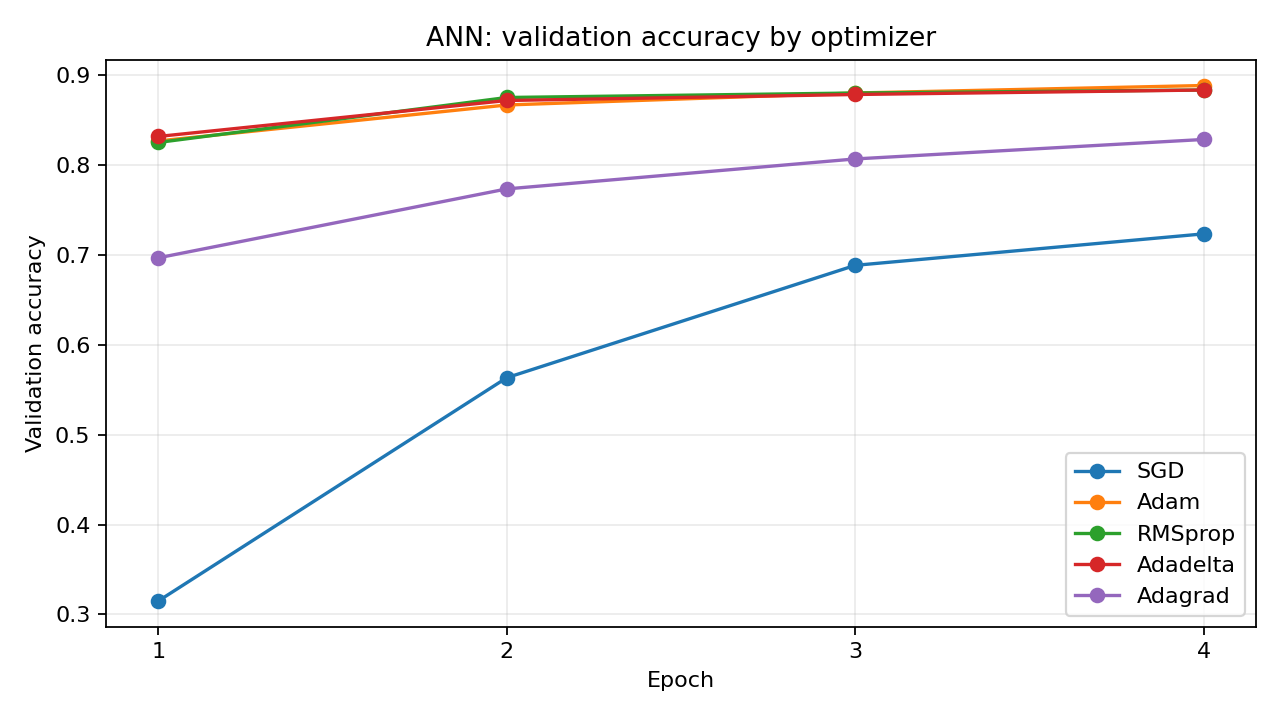

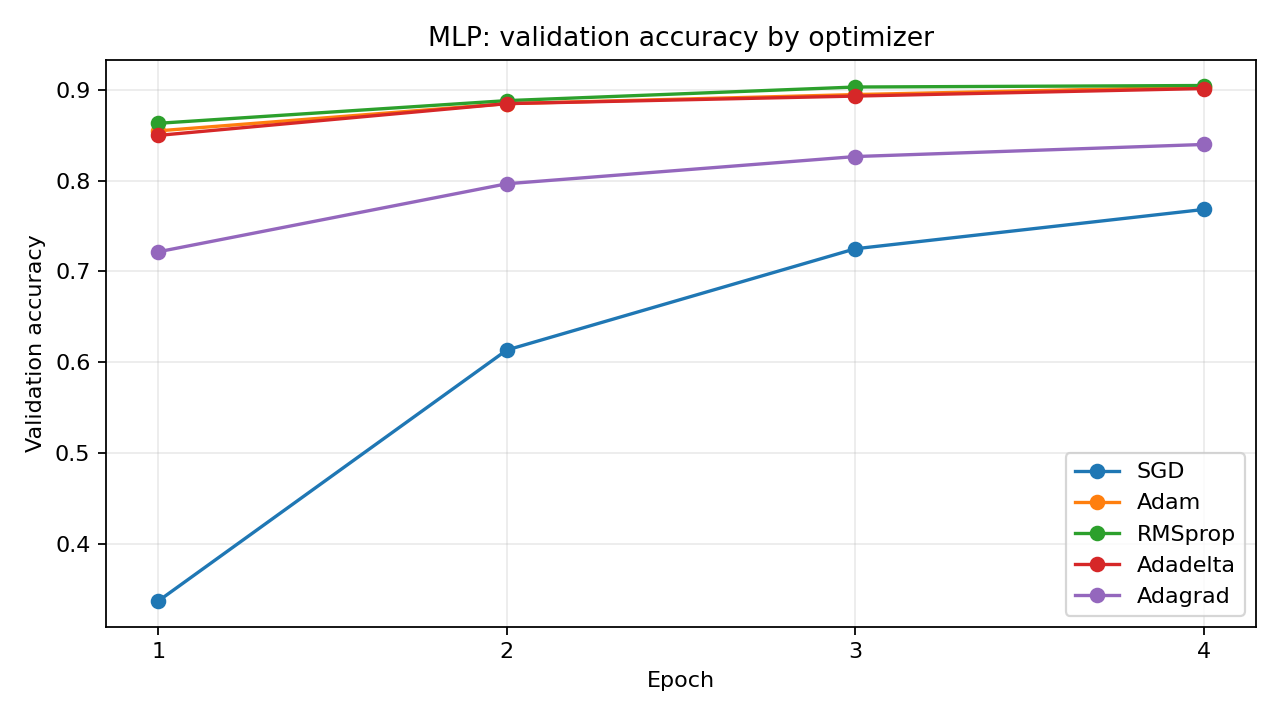

In [5]:
import pandas as pd  # Read the CSV files back as tables.
from IPython.display import Image, display  # Show the saved graphs inside the notebook.
print("Measured results (optimizer_results.csv):")  # Introduce the main table.
display(pd.read_csv(OUT / "optimizer_results.csv"))  # Show the real measured table.
print("Validation accuracy per epoch:")  # Introduce the convergence table.
display(pd.read_csv(OUT / "epoch_validation_accuracy.csv")  # Load the per-epoch values.
        .pivot_table(index=["model", "optimizer"], columns="epoch", values="val_accuracy"))  # One row per run.
for name in ["ann", "mlp"]:  # Show the graph of each architecture.
    display(Image(filename=str(OUT / f"{name}_validation_accuracy.png")))  # Display the saved PNG.


## Discussion

Within the ANN, Adam reached the highest best validation accuracy (0.888), with RMSprop and Adadelta tied just behind at 0.883. Within the MLP, RMSprop was highest (0.905), but Adam (0.903) and Adadelta (0.902) differ from it by only one or two of the 600 validation images. SGD (0.723 and 0.768) and Adagrad (0.828 and 0.840) trailed clearly, although each used one fixed learning rate for only four epochs. It is not justified to claim that an adaptive optimizer always improves results: this is a single seed, one small data subset and one untuned learning rate per optimizer, the leaders lie within noise, and the test ranking differs from the validation ranking (for the MLP, Adam has the best test accuracy, 0.898, while RMSprop scores 0.879). A different learning rate could reorder the results. The second hidden layer raised validation accuracy for all five optimizers, for example Adam from 0.888 to 0.903, so extra depth helped here; on the test set, however, RMSprop slipped slightly (0.883 to 0.879), and the leading optimizer changed between architectures.

### What changed, what stayed fixed, limitations
- **Changed:** only the optimizer object (SGD, Adam, RMSprop, Adadelta, Adagrad) and its learning rate; and, between the two blocks of runs, the architecture (ANN vs MLP).
- **Fixed:** image subsets, pixel scaling, seed, initial weights for each architecture, loss, EPOCHS = 4, BATCH_SIZE = 64, and shuffling seed.
- **Limitations:** one seed per run, only four epochs, 600 validation images (one image is 0.17 percentage points), learning rates not tuned, and training seconds measured on one CPU so they carry timing noise.

### Interpretation
**Which optimizer is best?** By best validation accuracy, Adam for the ANN (0.888) and RMSprop for the MLP (0.905). The top three adaptive optimizers are within about half a percentage point of each other, so none is clearly superior.

**Was the comparison controlled?** Yes for data, architecture, epochs, batch size, seed and initial weights, which were identical for every run. The learning rate is the one deliberate exception because each optimizer has a different natural scale.

**Why are the initial rates different?** SGD and Adagrad work with rates around 0.01, Adam and RMSprop with about 0.001, while Adadelta is conventionally started at 1.0 because it rescales its own step. They are illustrative starting points, not tuned values.

**ANN vs MLP** The MLP scored higher validation accuracy than the ANN with every optimizer (for example SGD 0.723 to 0.768), and its measured training time was similar or slightly higher (1.7 to 2.2 s against 1.5 to 2.0 s; single runs, so only indicative).

*Numbers above come from the run stored in this notebook; re-running (e.g. in Colab) may change seconds and slightly change accuracies.*